In [3]:
import numpy as np
from copy import deepcopy
import gwinc
import matplotlib.pyplot as plt

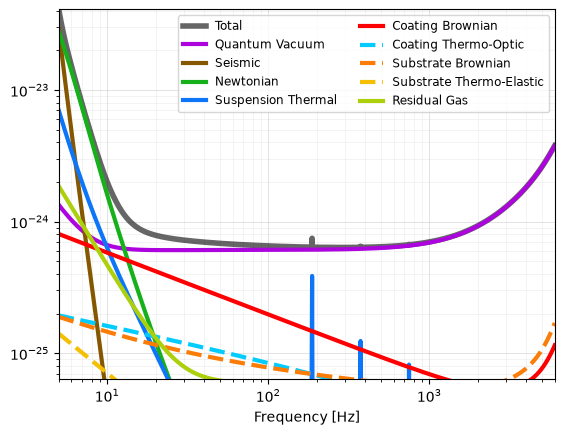

In [4]:
budget = gwinc.load_budget("../../../ifo/variant/OzCE-20.yaml")
ifo = deepcopy(budget.ifo)
fig = budget.run().plot()



In [114]:
gwinc_asd= budget.run().asd

In [115]:
gwinc_freq= budget.run().freq

In [5]:
class arm_cavity_stuff():
    def __init__(self, ifo):
        self.ifo = ifo
        self.params = {}
        self.rt_mat = None
        self.q_param = None
        self.gouy = None
        self.fsr = None
        self.msf = None
        self.homs = None



    def find_cav_params(self):
        self.params["length"] = deepcopy(self.ifo.Infrastructure.Length)
        self.params["Rc_ETM"] = deepcopy(self.ifo.Optics.Curvature.ETM)
        self.params["Rc_ITM"] = deepcopy(self.ifo.Optics.Curvature.ITM)

    def round_trip_mat(self):
        ref1_mat = np.array([ [1, 0], [-2/self.params["Rc_ITM"], 1]], dtype=np.complex128)
        ref2_mat = np.array([ [1, 0], [-2/self.params["Rc_ETM"], 1]], dtype=np.complex128)
        space_mat = np.array([ [1, self.params["length"]], [0, 1]], dtype=np.complex128)
        self.rt_mat = np.linalg.multi_dot([ref1_mat, space_mat, ref2_mat, space_mat])

    def solve_rt(self):
        m00 = self.rt_mat[0,0]
        m01 = self.rt_mat[0,1]
        m10 = self.rt_mat[1,0]
        m11 = self.rt_mat[1,1]
        a = m10
        b = m11 - m00
        c = -m01
        q_sol_1 = (-b + np.sqrt(b**2- 4*a*c))/(2*a)
        q_sol_2 = (-b - np.sqrt(b**2- 4*a*c))/(2*a)
        if np.imag(q_sol_1) > 0:
            self.q_param = q_sol_1
        elif np.imag(q_sol_2) > 0:
            self.q_param = q_sol_2
        else:
            self.q_param = 0
            print("Error: Cavity Unstable")
    
    def gouy_phase(self):
        A = self.rt_mat[0,0]
        B = self.rt_mat[0,1]
        C = self.rt_mat[1,0]
        D = self.rt_mat[1,1]
        self.gouy = np.real(2*np.arccos(np.sign(B)*np.sqrt((A+D+2)/4)))
        self.fsr = np.real((3e8/2/self.params["length"]))
        self.msf = np.real(self.gouy/(np.pi*2)*self.fsr)

    def homs_freq(self, n):
        mode_range = np.arange(n)
        self.homs = np.mod(self.msf*mode_range, self.fsr)
        
        

In [6]:
arm_cav_1 = arm_cavity_stuff(ifo)

In [7]:
arm_cav_1.find_cav_params()
arm_cav_1.params["Rc_ETM"] = 10957
arm_cav_1.params["Rc_ITM"] = 10957
arm_cav_1.round_trip_mat()
arm_cav_1.solve_rt()
arm_cav_1.gouy_phase()
arm_cav_1.homs_freq(20)

In [18]:
arm_cav_1.rt_mat

array([[-2.65063430e+00+0.j, -3.30126860e+04+0.j],
       [ 3.01293109e-04+0.j,  3.37522788e+00+0.j]])

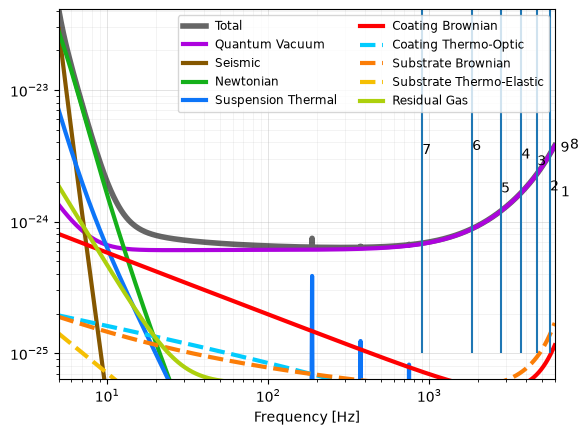

In [20]:
n=10

arm_cav_1.params["Rc_ETM"] = 10400
arm_cav_1.params["Rc_ITM"] = 10400
arm_cav_1.round_trip_mat()
arm_cav_1.solve_rt()
arm_cav_1.gouy_phase()
arm_cav_1.homs_freq(n)
fig2 = deepcopy(fig)
axes = fig2.gca()
axes.vlines(arm_cav_1.homs, 1e-25, 1e-22)
for i in np.arange(n):
    a = 3*np.random.random()+1
    axes.text(arm_cav_1.homs[i],1e-24*a, str(i))
fig2

In [12]:
arm_cav_1.homs

array([   0.        , 6067.52743904, 4635.05487808, 3202.58231713,
       1770.10975617,  337.63719521, 6405.16463425, 4972.6920733 ,
       3540.21951234, 2107.74695138])

In [13]:
ifo.Optics.Curvature.ITM

30000.0

In [14]:
ifo.Optics.Curvature.ETM

30000.0

In [15]:
ifo.Infrastructure.Length

20000.0

In [105]:
n = 11
n_rc = 5000
mode_trajectories = np.zeros(shape=(n_rc,n))
radii = np.linspace(10000, 12000, n_rc)
j=0
for i in radii:
    arm_cav_1.params["Rc_ETM"] = i
    arm_cav_1.params["Rc_ITM"] = i
    arm_cav_1.round_trip_mat()
    arm_cav_1.solve_rt()
    arm_cav_1.gouy_phase()
    arm_cav_1.homs_freq(n)
    mode_trajectories[j] = arm_cav_1.homs
    j+=1
    


In [106]:
for i in range(1,n):
    for j in range(n_rc-1):
        if (mode_trajectories.T[i][j] - mode_trajectories.T[i][j+1])<0:
            mode_trajectories.T[i][j] = np.nan

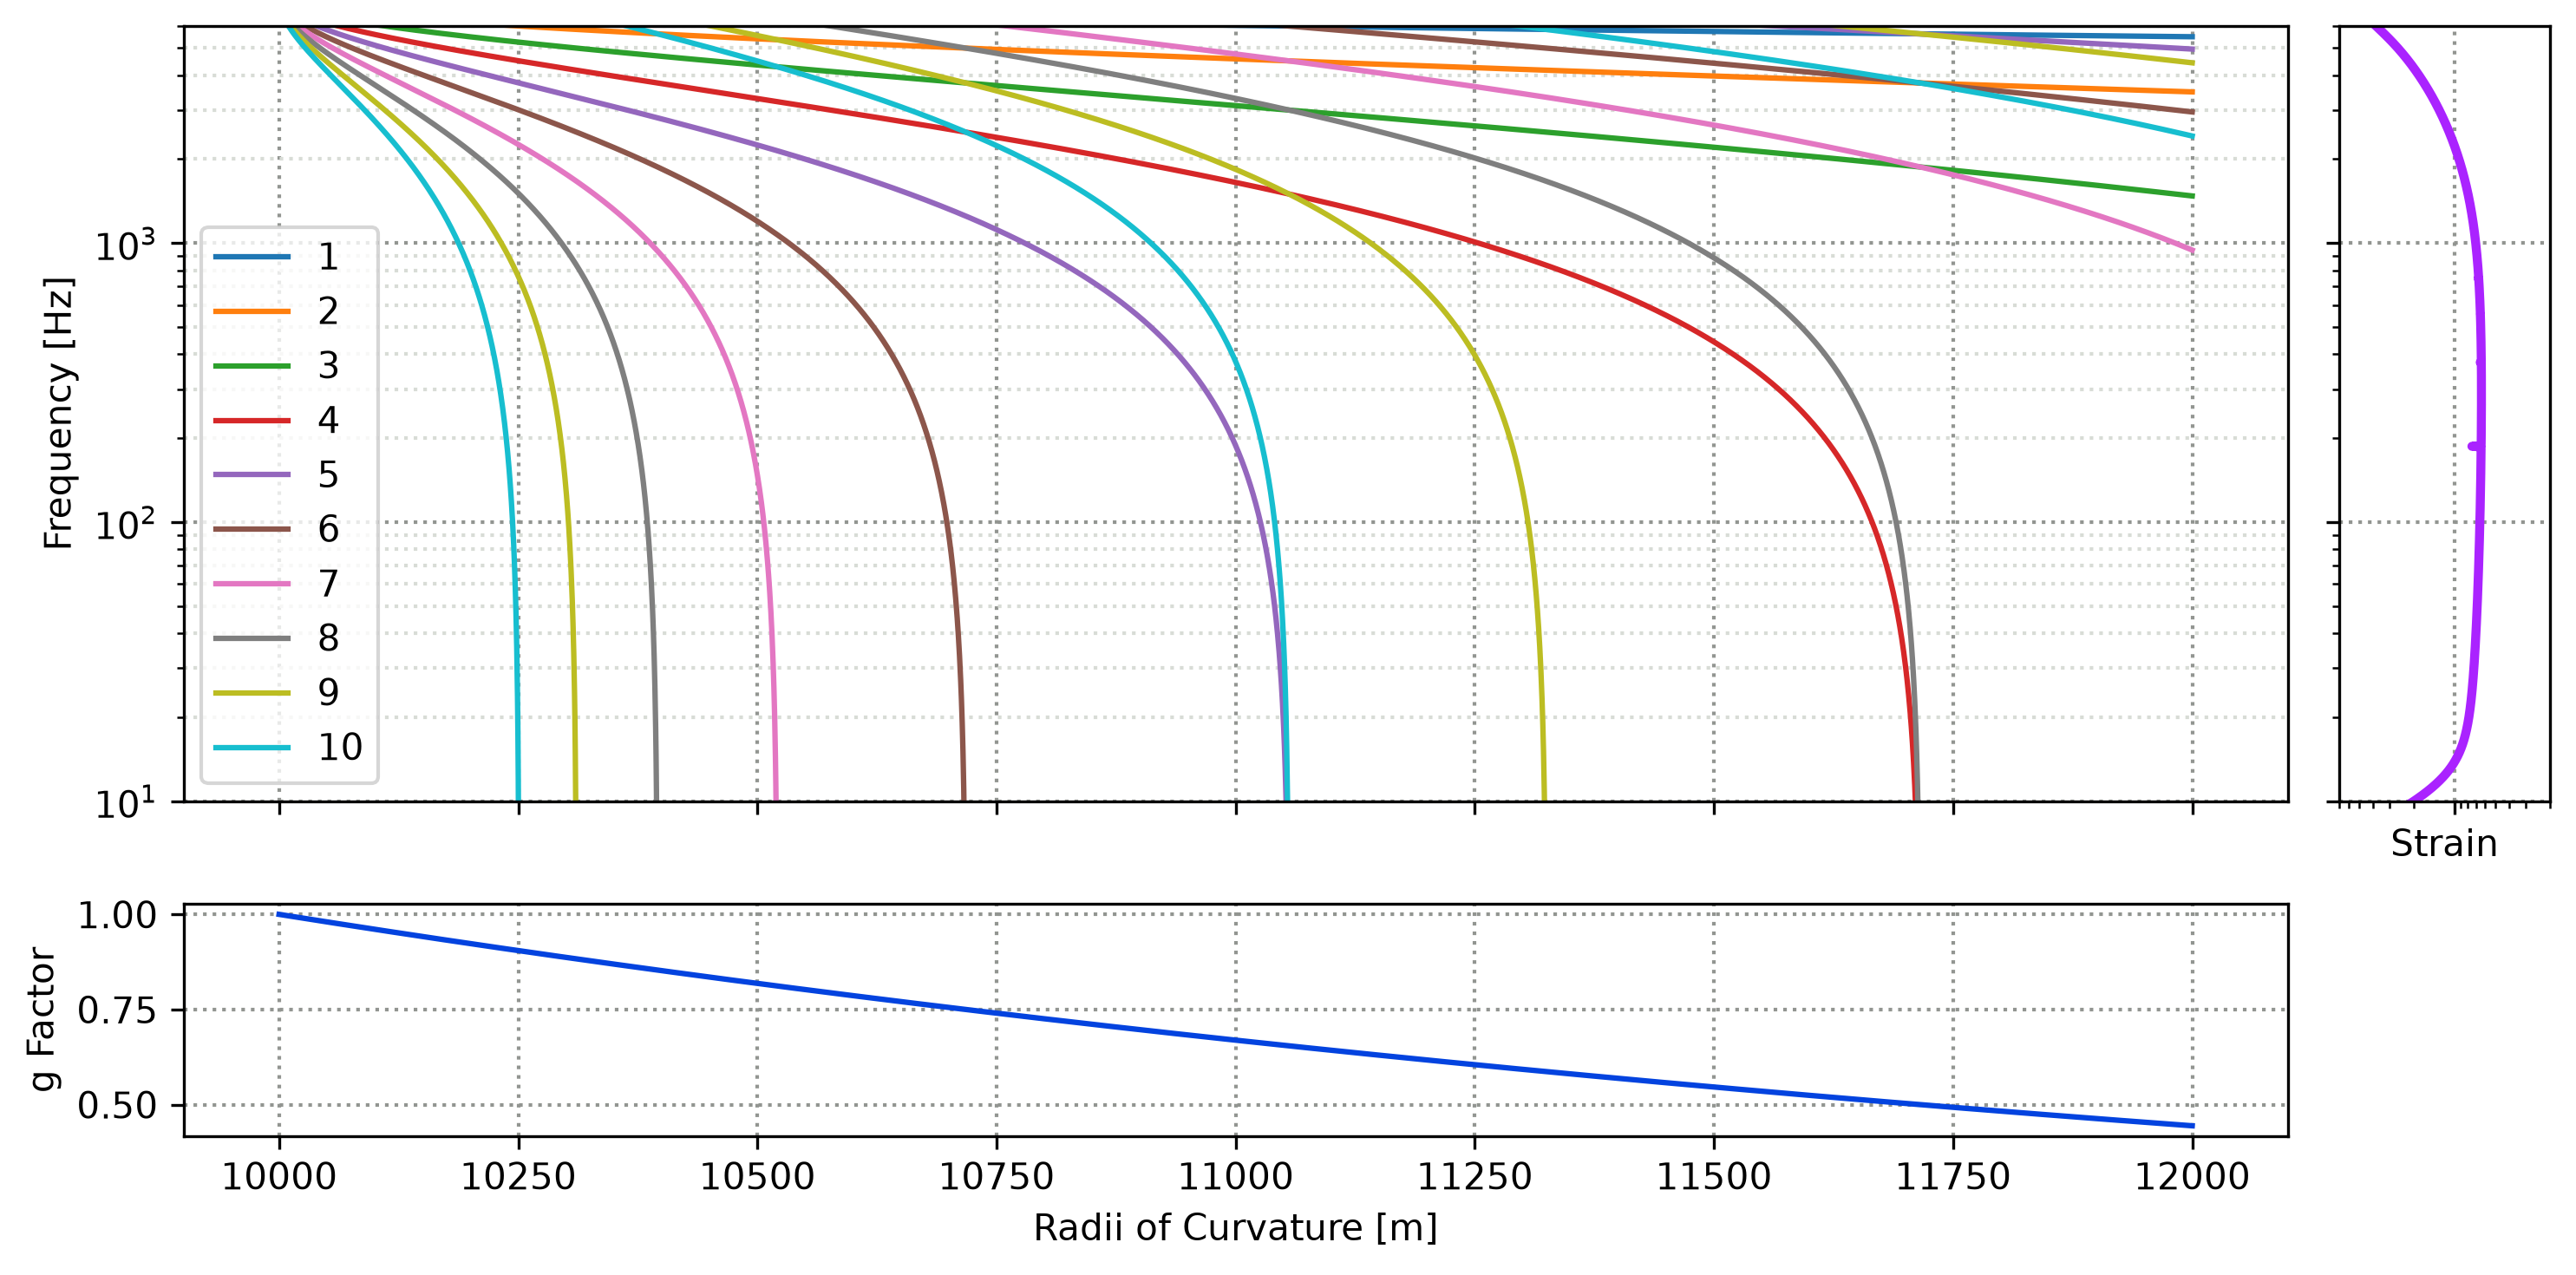

In [142]:
fig, [[ax,ax3],[ax2,ax4]] = plt.subplots(2,2, dpi=300, figsize=(10, 5), height_ratios=[1,0.3], tight_layout=True, sharex="col", width_ratios=[1,0.1], sharey="row")
#color_list = ["xkcd:black", "xkcd:cornflower","xkcd:raspberry", "xkcd:greenish blue", "xkcd:electric purple", "xkcd:electric blue", ]
fig.delaxes(ax4)
for i in range(1,n):
    ax.semilogy(radii,mode_trajectories.T[i], label=str(i))

ax2.plot(radii, (1-2e4/radii)**2, color="xkcd:blue")
ax3.loglog(gwinc_asd, gwinc_freq, color="xkcd:electric purple", linewidth=2.5)

ax.set_ylim(10, 6000)
ax2.set_xlabel("Radii of Curvature [m]")
ax.set_ylabel("Frequency [Hz]")
ax.legend()
ax.grid(linestyle=":", which="minor", color="xkcd:light grey", linewidth=1)
ax.grid(linestyle=":", which="major", color="xkcd:grey",linewidth=1)
ax2.grid(linestyle=":", which="major", color="xkcd:grey",linewidth=1)
ax2.set_ylabel("g Factor")
ax3.set_xlabel("Strain")

#ax3.xaxis.set_inverted(True)
ax3.set_xlim( 0.7e-23, 2e-25)
#ax3.x_ticks()
ax3.grid(linestyle=":", which="major", color="xkcd:grey",linewidth=1)
fig.savefig("modes_within_")

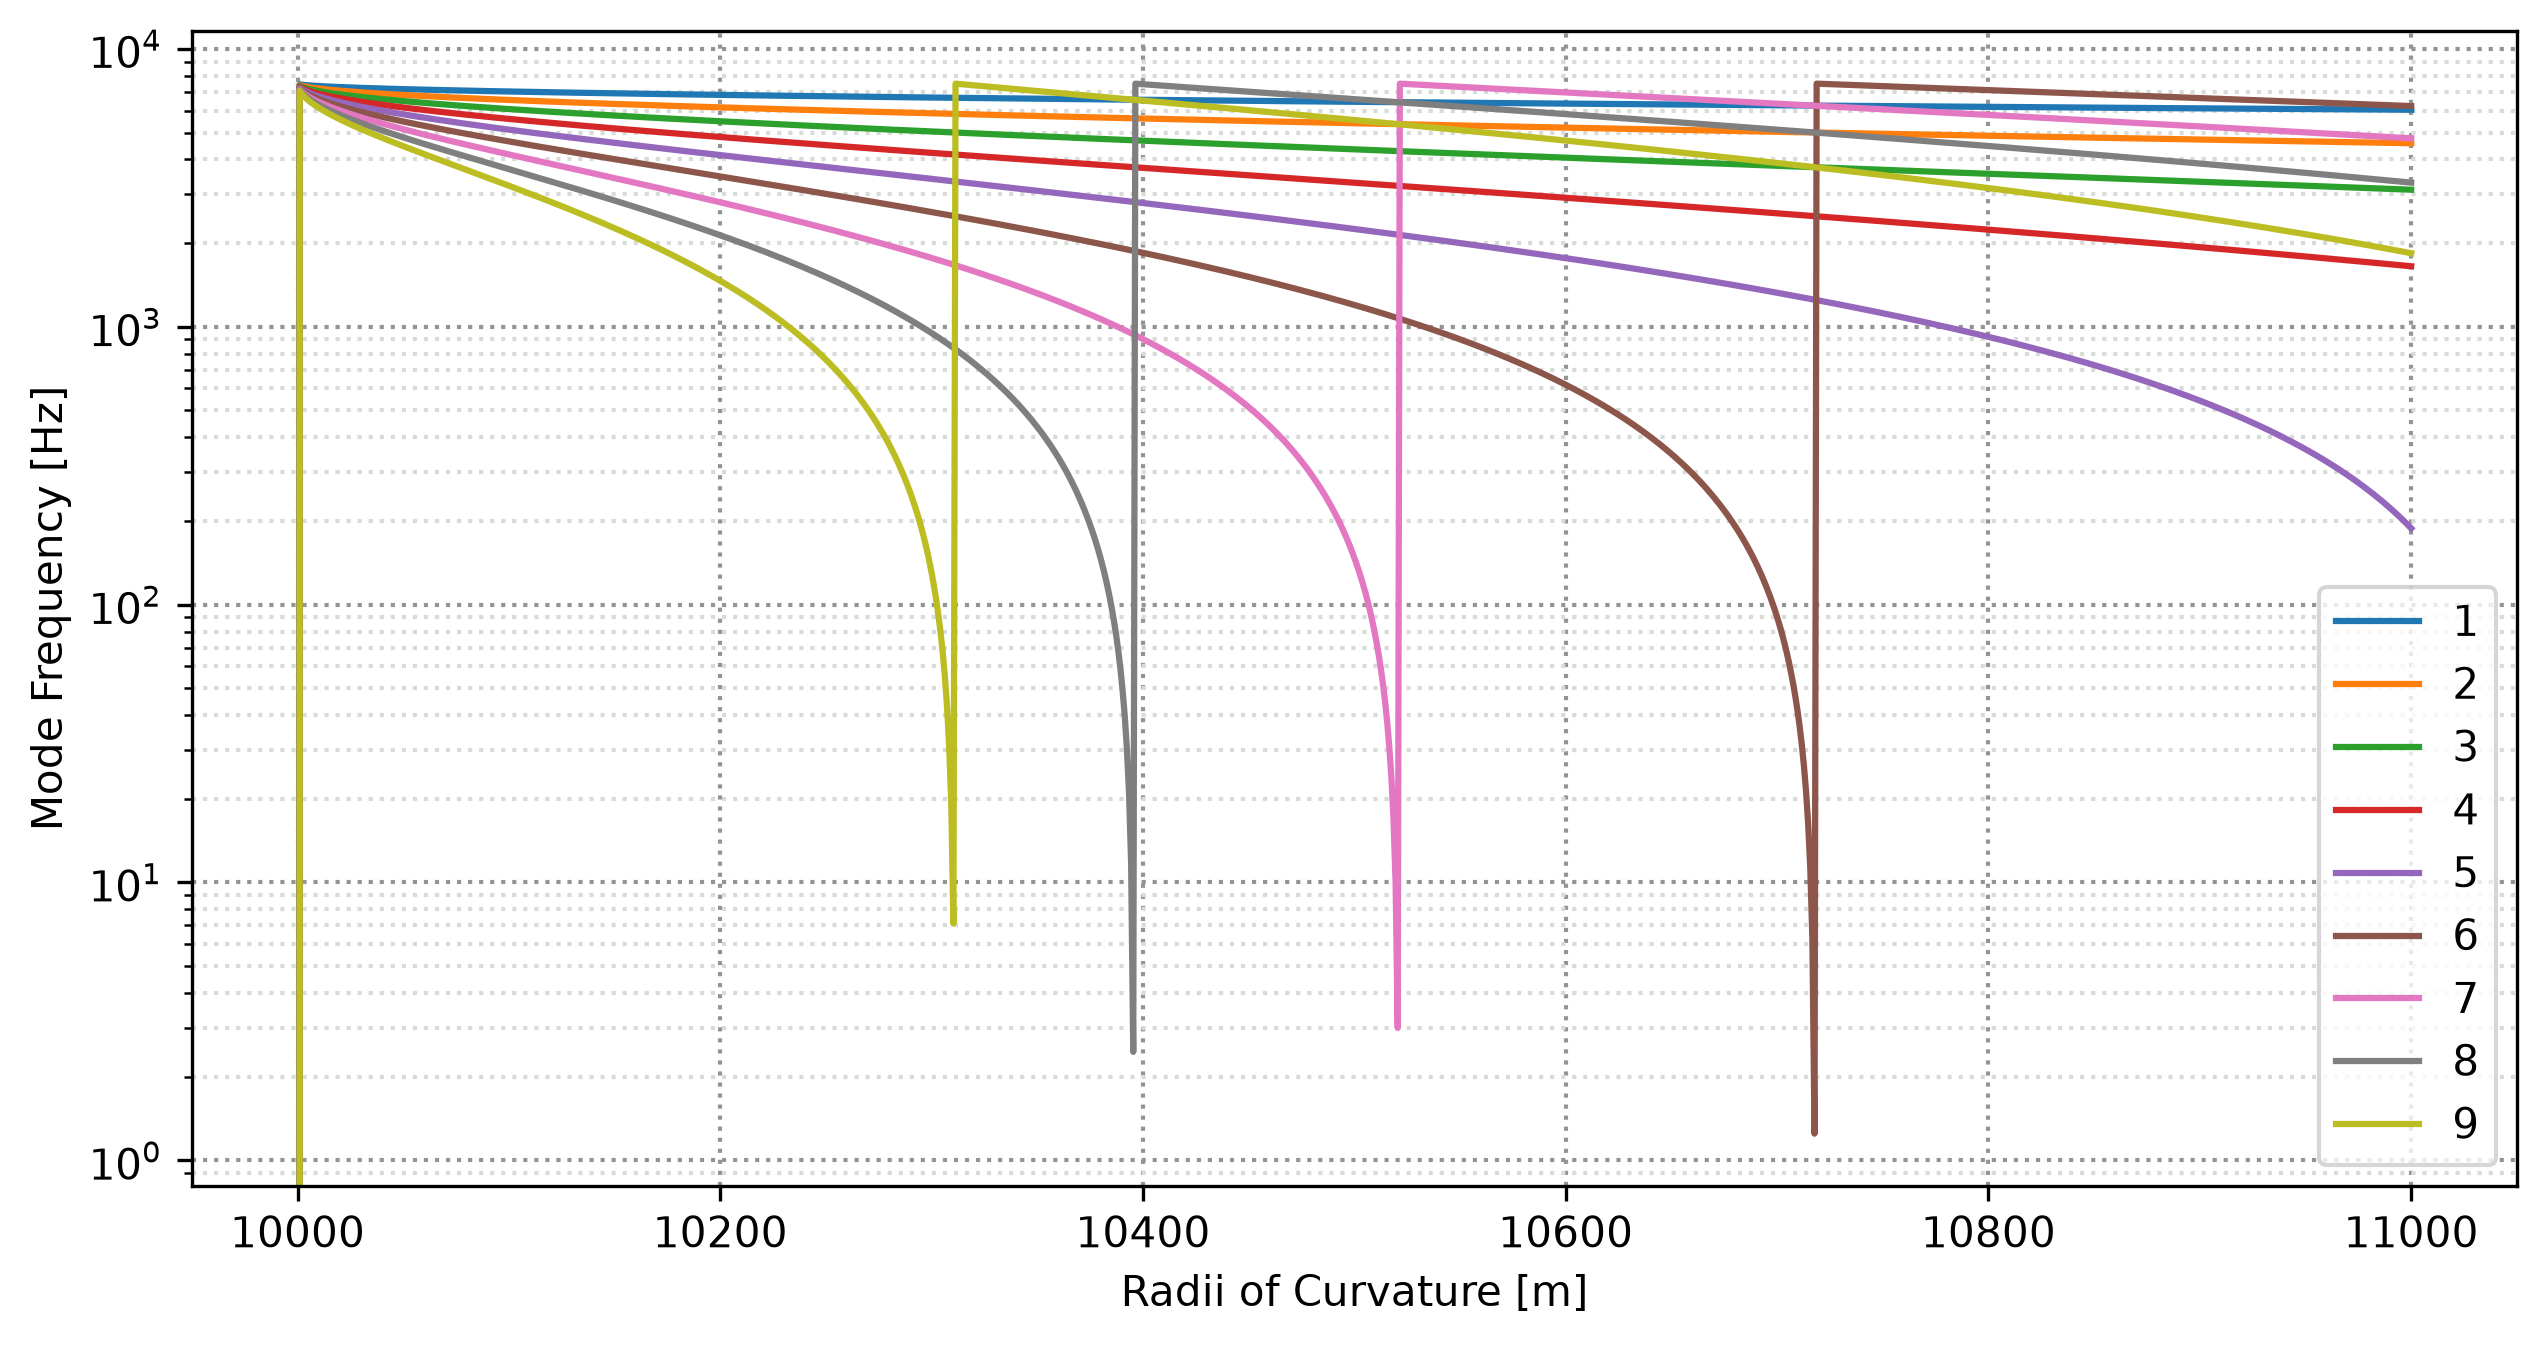

In [66]:
fig, ax = plt.subplots(1, dpi=300, figsize=(10, 5))
for i in range(1,n):
    ax.semilogy(radii,mode_trajectories.T[i], label=str(i))

#ax.set_ylim(30, 7000)
ax.set_xlabel("Radii of Curvature [m]")
ax.set_ylabel("Mode Frequency [Hz]")
ax.legend()
ax.grid(linestyle=":", which="minor", color="xkcd:light grey", linewidth=1)
ax.grid(linestyle=":", which="major", color="xkcd:grey",linewidth=1)